# Módulo 3 — Entregable integrador

Corre de punta a punta, para una fecha **nueva** (que no usamos antes), el
flujo descarga (cdsapi/ERA5) → verificación → organización, con las
funciones guardadas en `descarga.py` (Notebook 3).

> **📍 Nota para curso con 2 grupos:** el área de este entregable (`area=[-6, -80, -18, -68]`) cubre todo Perú; cada grupo la acota a su zona:
> - **Grupo 1 (Norte):** `area=[-3, -81.5, -13, -76.5]`.
> - **Grupo 2 (Sur):** `area=[-13, -73, -19, -69.5]`.
>
> **Extensión opcional (no evaluada) — Perú + ERA5-Land:** si al grupo le sobra tiempo, puede aplicar `obtener_entrada_wrf()` al área de `data/ogimet/coords_peru.json` para el `2024-12-13`, el día que tiene observaciones en `data/obs/`. Ver
> [`05_extension_opcional_peru.ipynb`](05_extension_opcional_peru.ipynb).
> El resultado se usa en el Módulo 5, Día 9.

In [1]:
import sys
sys.path.insert(0, ".")  # para poder importar descarga.py si ya existe en esta carpeta

import importlib
import descarga
importlib.reload(descarga)

from descarga import obtener_entrada_wrf, verificar_integridad
print("Funciones cargadas desde descarga.py:", [f for f in dir(descarga) if not f.startswith("_")])

Funciones cargadas desde descarga.py: ['NIVELES_PRESION_ERA5', 'NOMBRES_CORTOS_PRESION', 'NOMBRES_CORTOS_SUPERFICIE', 'VARIABLES_PRESION_ERA5', 'VARIABLES_SUPERFICIE_ERA5', 'cdsapi', 'descargar_era5_completo', 'obtener_entrada_wrf', 'os', 'pd', 'verificar_cobertura_vtable', 'verificar_integridad', 'xr']


## Caso nuevo: una fecha de mayo, dominio centro-sur del Perú

`obtener_entrada_wrf()` ya no recibe `variables`: siempre trae el conjunto
completo que pide `Vtable.ERA5` (Notebook 3, Ejercicio 4), niveles de
presión y superficie, verificados contra el Vtable.

In [2]:
ok, resultado = obtener_entrada_wrf(
    fecha_inicio="2026-05-04",
    fecha_fin="2026-05-05",
    area=[-6, -80, -18, -68],
    carpeta_destino="datos/entrada/era5",
)

print("¿Proceso exitoso?", ok)
print("Resultado:", resultado)

2026-07-24 20:23:07,018 INFO Request ID is 8288ef03-c61c-4915-b1fc-de4275ddd011


2026-07-24 20:23:08,027 INFO status has been updated to accepted


2026-07-24 20:23:43,286 INFO status has been updated to successful


9b8b56ae8c0b6c0f86df2c1ec44cbafa.nc:   0%|                                                              | 0.00/694k [00:00<?, ?B/s]

9b8b56ae8c0b6c0f86df2c1ec44cbafa.nc: 100%|███████████████████████████████████████████████████████| 694k/694k [00:01<00:00, 356kB/s]

/home/japq/.conda/envs/jap/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


¿Proceso exitoso? True
Resultado: ('datos/entrada/era5/2026-05-04_2026-05-05_niveles_presion.nc', 'datos/entrada/era5/2026-05-04_2026-05-05_superficie.nc')


## Verificación adicional: inspección de los archivos obtenidos

In [3]:
import xarray as xr

if ok:
    ruta_niveles, ruta_superficie = resultado
    ds_niveles = xr.open_dataset(ruta_niveles)
    ds_superficie = xr.open_dataset(ruta_superficie)
    print("Niveles de presión:", dict(ds_niveles.sizes), "| variables:", list(ds_niveles.data_vars))
    print("Superficie:         ", dict(ds_superficie.sizes), "| variables:", list(ds_superficie.data_vars))
else:
    print("El flujo falló, revisar el mensaje anterior antes de continuar.")

Niveles de presión: {'valid_time': 8, 'pressure_level': 37, 'latitude': 49, 'longitude': 49} | variables: ['t', 'u', 'v', 'q', 'z']
Superficie:          {'valid_time': 8, 'latitude': 49, 'longitude': 49} | variables: ['t2m', 'd2m', 'u10', 'v10', 'sp', 'msl', 'skt', 'siconc', 'sd', 'lsm', 'z', 'stl1', 'stl2', 'stl3', 'stl4', 'swvl1', 'swvl2', 'swvl3', 'swvl4']


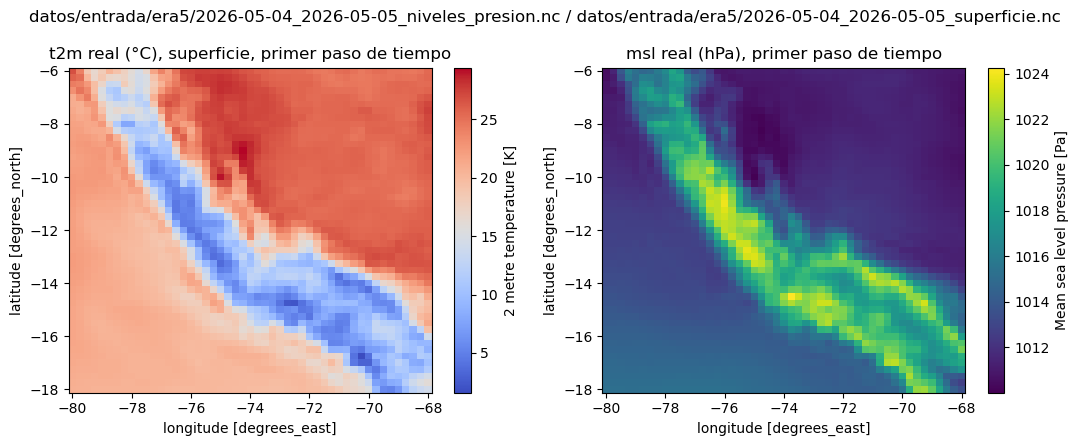

In [4]:
import matplotlib.pyplot as plt

if ok:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    (ds_superficie["t2m"].isel(valid_time=0) - 273.15).plot(ax=axes[0], cmap="coolwarm")
    axes[0].set_title("t2m real (°C), superficie, primer paso de tiempo")
    (ds_superficie["msl"].isel(valid_time=0) / 100).plot(ax=axes[1], cmap="viridis")
    axes[1].set_title("msl real (hPa), primer paso de tiempo")
    fig.suptitle(f"{ruta_niveles} / {ruta_superficie}")
    fig.tight_layout()
    plt.show()

## Caso de contraste: provocar un fallo (rango de fechas invertido)

Para provocar un fallo basta un error común: invertir `fecha_inicio` y
`fecha_fin`. Entonces `pd.date_range()` devuelve una lista vacía de días.
Sin control, el código fallaría más adelante con un mensaje difícil de
entender (`index 0 is out of bounds…`). Por eso `descarga.py` revisa las
fechas **antes** de contactar al servidor y lanza un `ValueError` que dice
qué pasó; `obtener_entrada_wrf` lo captura y lo devuelve como mensaje.

In [5]:
ok_falla, resultado_falla = obtener_entrada_wrf(
    fecha_inicio="2026-05-10",
    fecha_fin="2026-05-05",  # fin ANTES que inicio -- error real, no simulado
    area=[-6, -80, -18, -68],
    carpeta_destino="datos/entrada/era5",
)
print("¿Proceso exitoso?", ok_falla)
print("Resultado:", resultado_falla)

¿Proceso exitoso? False
Resultado: Fallo en la descarga: IndexError: index 0 is out of bounds for axis 0 with size 0


## Pregunta de cierre del módulo

**Pregunta:** para un caso de estudio "simular una helada en la sierra sur
la próxima semana" frente a "simular una lluvia intensa ocurrida en marzo
de 2023", ¿qué fuente de datos de entrada corresponde en cada caso y por
qué?

✍️ **Tu respuesta** (doble clic en esta celda y escribe debajo):

…

<details>
<summary>Ver una respuesta modelo (ábrela solo después de escribir la tuya)</summary>

**Helada en la sierra sur la próxima semana:** es un evento futuro, así que
corresponde **GFS** (pronóstico operativo), descargado con Herbie, del ciclo
más reciente disponible.

**Lluvia intensa de marzo de 2023:** ya ocurrió, así que corresponde
**ERA5** (reanálisis), descargado con `cdsapi`: la mejor estimación
retrospectiva y consistente de la atmósfera en esa fecha. Si el evento
fuera muy reciente y ERA5 todavía no lo cubriera, la alternativa es **FNL**,
un análisis que se publica con mucho menos rezago.

Regla general: evento pasado → reanálisis (ERA5, o FNL si ERA5 aún no
llega); evento futuro → pronóstico (GFS).
</details>

---
**Fin del Módulo 3.** Siguiente:
[Módulo 4 — Lectura y visualización de salidas WRF](../../modulo_04_lectura_visualizacion_wrf/README.md).